# 03 · Can a model beat NOAA's storm forecast?

Notebook 02 set the bar: NOAA's published probabilities are the best of the simple forecasts, with a next-day Brier skill of about 11% on 2022–2025. This notebook asks whether a model can do better with the same question (at 21:00 UTC, the chance of a storm on each of the next three UT days) and the data from notebooks 01 and 02.

**Four model families:**
- **Logistic regression** on the daily features below.
- **Gradient boosting** on the same features.
- **A recurrent network (GRU)** that reads the raw hourly solar wind and Kp of the last three days, alongside the daily features, instead of relying on summaries of them.
- **Gradient boosting plus NOAA's forecast as an input:** not a replacement for NOAA, but a check on whether a model can improve NOAA's numbers.

**The protocol, as in the other projects:** each family's settings are chosen on 2017–2021 while training on 1996–2016. The chosen settings are then retrained on 1996–2021 and scored once on 2022–2025, on the same days as NOAA's forecasts. This takes a few minutes, mostly the recurrent network.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path("..") / "src"))
from features import daily_storms, hourly_sequences, issue_features, lead_features
from sequence import fit_predict
from storms import load_kp, load_noaa_forecasts, load_omni

warnings.filterwarnings("ignore", category=RuntimeWarning)
LEADS = (1, 2, 3)
TRAIN, VALID, TRAIN_ALL, TEST = ("1996", "2016"), ("2017", "2021"), ("1996", "2021"), ("2022", "2025")

kp = load_kp().loc["1995":]
omni = load_omni()
noaa = load_noaa_forecasts()
noaa["noaa"] = noaa["p_minor"] + noaa["p_major"]
days = daily_storms(kp)
issue = issue_features(kp, omni)

frames = {}
for lead in LEADS:
    frame = lead_features(issue, days, lead)
    frame["noaa"] = noaa[noaa["lead_days"] == lead].set_index("issued")["noaa"].reindex(frame.index).to_numpy()
    frames[lead] = frame.loc["1996":"2025"].dropna(subset=["storm"])
FEATURES = [c for c in frames[1].columns if c not in ("storm", "target_day", "noaa")]
sequences = hourly_sequences(kp, omni, frames[1].index)
print(f"{len(frames[1]):,} issue days, {len(FEATURES)} daily features, hourly sequences {sequences.shape[1:]}")

10,958 issue days, 25 daily features, hourly sequences (72, 8)


## What the models know at 21:00 UTC

Every input is something a forecaster has at the issue time. The check after this list changes everything from 21:00 UTC onward on one issue day (the May 2024 storm) and confirms that day's inputs stay the same.

- **Kp so far:** today's highest and mean Kp before 21:00, the latest three-hour value, the highest Kp on each of the last three days, storm days in the last week, and the storm rate over the past year.
- **Solar wind over the last 24 hours:** mean and peak speed, speed over the last three hours and how much it jumped, the most southward Bz, the average southward field, hours with Bz below −5 nT, peak electric field, density, pressure, and field strength.
- **The Sun:** F10.7 radio flux and the 27-day mean sunspot number.
- **The 27-day echo of the target day:** its highest Kp one and two solar rotations earlier.

In [2]:
# Change every Kp value and solar wind hour from 21:00 UTC onward; the issue day's inputs must not move.
probe = pd.Timestamp("2024-05-10")
kp_changed, omni_changed = kp.copy(), omni.copy()
kp_changed.loc[kp_changed.index >= probe + pd.Timedelta(hours=21), "kp"] = 0.0
omni_changed.loc[omni_changed.index >= probe + pd.Timedelta(hours=21)] = 1.0
same_daily = issue_features(kp_changed, omni_changed).loc[probe].equals(issue.loc[probe])
same_hourly = np.array_equal(hourly_sequences(kp_changed, omni_changed, [probe]), hourly_sequences(kp, omni, [probe]), equal_nan=True)
print(f"daily inputs unchanged: {same_daily}; hourly sequence unchanged: {same_hourly}")
assert same_daily and same_hourly

daily inputs unchanged: True; hourly sequence unchanged: True


In [3]:
def years(index, span):
    return (index >= span[0]) & (index <= f"{span[1]}-12-31")


def logistic(c):
    return lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=c, max_iter=2000))


def boosted(**settings):
    return lambda: HistGradientBoostingClassifier(min_samples_leaf=40, l2_regularization=1.0, random_state=0, **settings)


BOOSTED = [{"learning_rate": 0.05, "max_leaf_nodes": 15, "max_iter": 200},
           {"learning_rate": 0.05, "max_leaf_nodes": 31, "max_iter": 300},
           {"learning_rate": 0.03, "max_leaf_nodes": 7, "max_iter": 400}]
FAMILIES = {
    "logistic regression": ([{"C": c} for c in (0.01, 0.1, 1.0)], lambda s: logistic(s["C"]), False),
    "gradient boosting": (BOOSTED, lambda s: boosted(**s), False),
    "gradient boosting + NOAA": (BOOSTED, lambda s: boosted(**s), True),
}


def tabular(train_span, score_span, make, with_noaa):
    """Storm probabilities for each lead, on the score years' days that have a NOAA forecast."""
    out = {}
    for lead in LEADS:
        frame = frames[lead]
        columns = FEATURES + (["noaa"] if with_noaa else [])
        fit = years(frame.index, train_span) & (frame["noaa"].notna() if with_noaa else True)
        score = years(frame.index, score_span) & frame["noaa"].notna()
        model = make().fit(frame.loc[fit, columns], frame.loc[fit, "storm"])
        out[lead] = pd.Series(model.predict_proba(frame.loc[score, columns])[:, 1], index=frame.index[score])
    return out


def recurrent(train_span, score_span, hidden):
    """The network's probabilities, trained on the span but stopped early on its last two years."""
    index = frames[1].index
    targets = np.column_stack([frames[lead]["storm"].to_numpy() for lead in LEADS])
    usable = ~np.isnan(targets).any(axis=1)
    train = years(index, train_span) & usable
    stop = train & (index > pd.Timestamp(f"{int(train_span[1]) - 1}-01-01"))
    score = years(index, score_span) & frames[1]["noaa"].notna().to_numpy()
    p = fit_predict(sequences, frames[1][FEATURES].to_numpy(dtype=np.float32), np.nan_to_num(targets),
                    train & ~stop, stop, score, hidden=hidden)
    return {lead: pd.Series(p[:, i], index=index[score]) for i, lead in enumerate(LEADS)}


def log_loss(y, p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def mean_log_loss(predictions):
    return np.mean([log_loss(frames[lead].loc[p.index, "storm"].to_numpy(), p.to_numpy()) for lead, p in predictions.items()])

## Choosing settings on 2017–2021

Mean log loss over the three lead times (lower is better). For reference, NOAA's own forecast scores on the same days:

In [4]:
noaa_valid = {lead: frames[lead].loc[years(frames[lead].index, VALID) & frames[lead]["noaa"].notna(), "noaa"] for lead in LEADS}
print(f"NOAA, as published: {mean_log_loss(noaa_valid):.4f}\n")

chosen, rows = {}, []
for family, (options, maker, with_noaa) in FAMILIES.items():
    for settings in options:
        loss = mean_log_loss(tabular(TRAIN, VALID, maker(settings), with_noaa))
        rows.append({"family": family, "settings": settings, "log loss": loss})
        if family not in chosen or loss < chosen[family]["log loss"]:
            chosen[family] = {"settings": settings, "log loss": loss}
for hidden in (32, 64):
    loss = mean_log_loss(recurrent(TRAIN, VALID, hidden))
    rows.append({"family": "recurrent network", "settings": {"hidden units": hidden}, "log loss": loss})
    if "recurrent network" not in chosen or loss < chosen["recurrent network"]["log loss"]:
        chosen["recurrent network"] = {"settings": {"hidden units": hidden}, "log loss": loss}

pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows).round(4)

NOAA, as published: 0.2087



,family,settings,log loss
0,logistic regression,{'C': 0.01},0.2263
1,logistic regression,{'C': 0.1},0.2255
2,logistic regression,{'C': 1.0},0.2253
3,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'max_iter': 200}",0.2209
4,gradient boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_iter': 300}",0.2350
5,gradient boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 7, 'max_iter': 400}",0.2186
6,gradient boosting + NOAA,"{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'max_iter': 200}",0.2026
7,gradient boosting + NOAA,"{'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_iter': 300}",0.2130
8,gradient boosting + NOAA,"{'learning_rate': 0.03, 'max_leaf_nodes': 7, 'max_iter': 400}",0.2017
9,recurrent network,{'hidden units': 32},0.2318


In [5]:
winner = min(chosen, key=lambda f: chosen[f]["log loss"])
for family, c in chosen.items():
    print(f"{family:<26} {c['log loss']:.4f}  {c['settings']}")
print(f"\nBest on 2017–2021: {winner}")

logistic regression        0.2253  {'C': 1.0}
gradient boosting          0.2186  {'learning_rate': 0.03, 'max_leaf_nodes': 7, 'max_iter': 400}
gradient boosting + NOAA   0.2017  {'learning_rate': 0.03, 'max_leaf_nodes': 7, 'max_iter': 400}
recurrent network          0.2318  {'hidden units': 32}

Best on 2017–2021: gradient boosting + NOAA


## The test: 2022–2025, once

Each family's chosen settings, retrained on 1996–2021, against NOAA's published forecast on the same days. The interval is a paired bootstrap over test days for the difference in Brier score from NOAA's (below zero means better than NOAA).

In [6]:
test_predictions = {}
for family, c in chosen.items():
    if family == "recurrent network":
        test_predictions[family] = recurrent(TRAIN_ALL, TEST, c["settings"]["hidden units"])
    else:
        options, maker, with_noaa = FAMILIES[family]
        test_predictions[family] = tabular(TRAIN_ALL, TEST, maker(c["settings"]), with_noaa)

rng = np.random.default_rng(0)
results = []
for lead in LEADS:
    frame = frames[lead]
    rows_ = years(frame.index, TEST) & frame["noaa"].notna()
    y = frame.loc[rows_, "storm"].to_numpy()
    climatology = np.mean((frame.loc[rows_, "storm_rate_last_year"].to_numpy() - y) ** 2)
    contenders = {"NOAA, as published": frame.loc[rows_, "noaa"].to_numpy(),
                  **{family: p[lead].reindex(frame.index[rows_]).to_numpy() for family, p in test_predictions.items()}}
    resample = rng.integers(0, len(y), (2000, len(y)))
    for name, p in contenders.items():
        brier = (p - y) ** 2
        row = {"lead days": lead, "forecast": name, "Brier skill": 1 - brier.mean() / climatology, "log loss": log_loss(y, p)}
        if name != "NOAA, as published":
            difference = brier - (contenders["NOAA, as published"] - y) ** 2
            low, high = np.percentile(difference[resample].mean(axis=1), [2.5, 97.5])
            row.update({"Brier minus NOAA": difference.mean(), "low": low, "high": high})
        results.append(row)
results = pd.DataFrame(results)
print(f"{rows_.sum():,} test days per lead time, {y.mean():.1%} with a storm")
results.round(4)

1,449 test days per lead time, 17.2% with a storm


,lead days,forecast,Brier skill,log loss,Brier minus NOAA,low,high
0,1,"NOAA, as published",0.1149,0.4058,NaN,NaN,NaN
1,1,logistic regression,0.1493,0.3929,-0.0048,-0.0132,0.0032
2,1,gradient boosting,0.1610,0.3871,-0.0065,-0.0147,0.0014
3,1,gradient boosting + NOAA,0.1652,0.3767,-0.0070,-0.0131,-0.0012
4,1,recurrent network,0.1935,0.3718,-0.0110,-0.0197,-0.0026
5,2,"NOAA, as published",0.0623,0.4406,NaN,NaN,NaN
6,2,logistic regression,0.0378,0.4381,0.0035,-0.0037,0.0115
7,2,gradient boosting,0.0345,0.4400,0.0039,-0.0032,0.0116
8,2,gradient boosting + NOAA,0.0677,0.4247,-0.0008,-0.0051,0.0035
9,2,recurrent network,0.0112,0.4499,0.0073,0.0001,0.0149


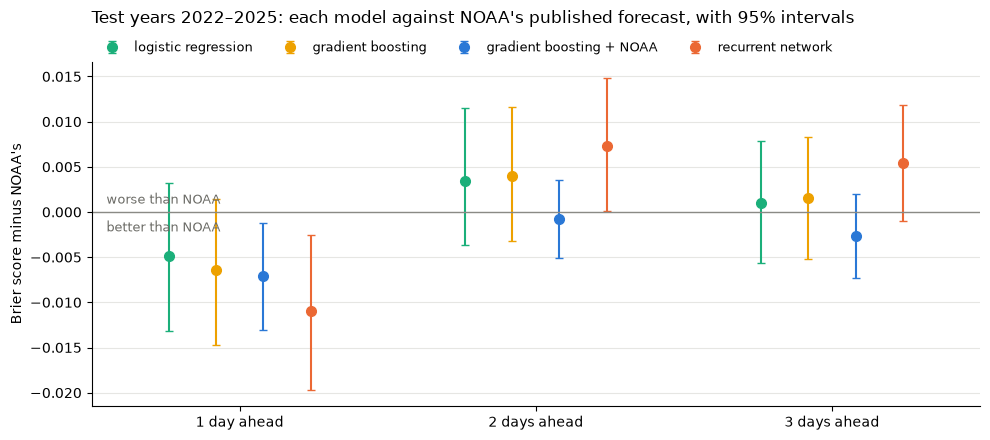

In [7]:
families = [f for f in chosen]
colors = {"logistic regression": "#1baf7a", "gradient boosting": "#eda100", "gradient boosting + NOAA": "#2a78d6", "recurrent network": "#eb6834"}
fig, ax = plt.subplots(figsize=(10, 4.5))
offsets = np.linspace(-0.24, 0.24, len(families))
for offset, family in zip(offsets, families):
    part = results[results["forecast"] == family]
    x = part["lead days"] + offset
    ax.errorbar(x, part["Brier minus NOAA"], yerr=[part["Brier minus NOAA"] - part["low"], part["high"] - part["Brier minus NOAA"]],
                fmt="o", color=colors[family], markersize=7, capsize=3, linewidth=1.5, label=family)
ax.axhline(0, color="#8a8a85", linewidth=1)
ax.annotate("better than NOAA", (0.55, 0), xytext=(0, -14), textcoords="offset points", fontsize=9, color="#6b6b66")
ax.annotate("worse than NOAA", (0.55, 0), xytext=(0, 6), textcoords="offset points", fontsize=9, color="#6b6b66")
ax.set_xlim(0.5, 3.5)
ax.set_xticks(LEADS, ["1 day ahead", "2 days ahead", "3 days ahead"])
ax.set_ylabel("Brier score minus NOAA's")
ax.set_title("Test years 2022–2025: each model against NOAA's published forecast, with 95% intervals", loc="left", pad=28)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncols=4, borderaxespad=0.2, fontsize=9)
ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Is the chosen model calibrated?

Next-day forecasts on the test years, the validation winner against NOAA:

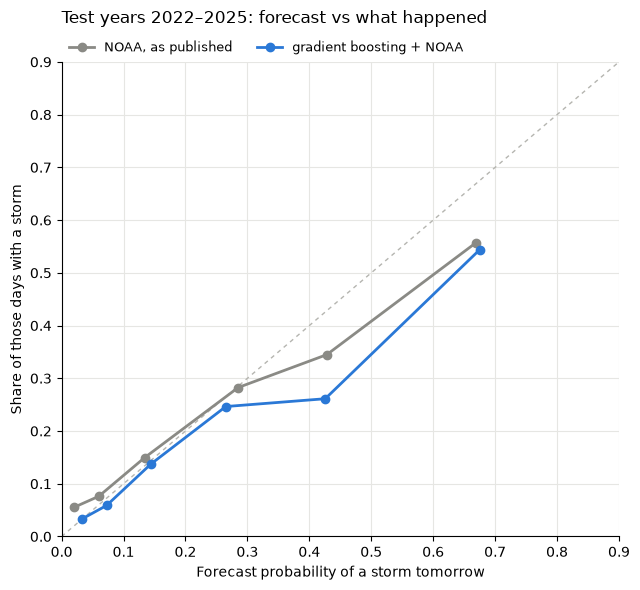

In [8]:
frame = frames[1]
rows_ = years(frame.index, TEST) & frame["noaa"].notna()
check = pd.DataFrame({"storm": frame.loc[rows_, "storm"], "NOAA, as published": frame.loc[rows_, "noaa"],
                      winner: test_predictions[winner][1].reindex(frame.index[rows_])})
bins = [0, 0.05, 0.1, 0.2, 0.35, 0.5, 1.0]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color="#b5b5b0", linewidth=1, linestyle=(0, (3, 3)))
for name, color in (("NOAA, as published", "#8a8a85"), (winner, colors[winner])):
    groups = check.groupby(pd.cut(check[name], bins), observed=True)
    ax.plot(groups[name].mean(), groups["storm"].mean(), marker="o", color=color, linewidth=2, label=name)
ax.set_xlim(0, 0.9)
ax.set_ylim(0, 0.9)
ax.set_xlabel("Forecast probability of a storm tomorrow")
ax.set_ylabel("Share of those days with a storm")
ax.set_title("Test years 2022–2025: forecast vs what happened", loc="left", pad=28)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncols=2, borderaxespad=0.2, fontsize=9)
ax.grid(color="#e6e6e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## What the model leans on

Permutation importance for the next-day gradient boosting model without NOAA's input, on 2017–2021: how much the log loss worsens when one feature's values are shuffled across days.

In [9]:
frame = frames[1]
fit, score = years(frame.index, TRAIN), years(frame.index, VALID)
model = boosted(**chosen["gradient boosting"]["settings"])().fit(frame.loc[fit, FEATURES], frame.loc[fit, "storm"])
importance = permutation_importance(model, frame.loc[score, FEATURES], frame.loc[score, "storm"], scoring="neg_log_loss",
                                    n_repeats=10, random_state=0)
ranked = pd.Series(importance.importances_mean, index=FEATURES).sort_values(ascending=False)
ranked.head(10).round(4).to_frame("log loss increase when shuffled")

,log loss increase when shuffled
kp_last,0.0114
echo_26_28_max,0.0101
echo_27,0.0053
kp_today_mean,0.0036
density_max_24h,0.0015
bz_min_24h,0.0011
f107,0.0011
speed_last_3h,0.0009
southward_last_3h,0.0008
echo_54,0.0007


## Saving the results

For the project's web page.

In [10]:
RESULTS = Path("..") / "results"
RESULTS.mkdir(exist_ok=True)
results.round(5).to_csv(RESULTS / "test_scores.csv", index=False)
pd.DataFrame([{"family": f, "log_loss": c["log loss"], "settings": str(c["settings"])} for f, c in chosen.items()]).round(5).to_csv(RESULTS / "validation_choice.csv", index=False)
check.round(4).to_csv(RESULTS / "next_day_test_forecasts.csv")

## What this shows

- **Next day, the models beat NOAA's published forecast.** On 2022–2025 all four had a lower Brier score than NOAA, and two by more than chance: the validation pick, gradient boosting with NOAA's forecast as an input (Brier skill about 17% against NOAA's 11%), and the recurrent network (about 19%).
- **The recurrent network's win isn't a reliable one.** It was the worst of the four on 2017–2021, and two days ahead it was worse than NOAA by more than chance. Its next-day result may reflect the storm-heavy test years suiting it; one period can't tell.
- **Two and three days ahead, nothing beats NOAA beyond chance**, and the models without NOAA's input fall behind it two days out. That's where NOAA's forecasters' view of coronal mass ejections leaving the Sun pays off, and nothing in this data can see those.
- **Gradient boosting with NOAA's forecast as an input is the only model at or ahead of NOAA at every lead time.** The practical result isn't a replacement for NOAA but a correction layered on top of it.
- **What the models lean on:** the latest Kp, then the 27-day echo, which was nearly worthless on its own in notebook 02 but is the second most useful input alongside everything else. The last day's solar wind adds less than expected: it reaches Earth within an hour of being measured, so by 21:00 UTC its effect is mostly already in Kp.

**Limits:**
- **Hindsight data.** The models are trained and tested on final, cleaned data: definitive Kp and quality-checked solar wind. NOAA forecasts in real time from preliminary Kp and live solar wind with gaps. That flatters the models, most of all the next day, when the latest Kp matters most. A fair operational test needs archived real-time data.
- **Different targets.** NOAA forecasts a mid-latitude K index, not the planetary Kp scored here (notebook 02).
- **One solar maximum.** Four test years, one active period.